# 02 · Simulasi Deteksi & Mitigasi DDoS pada SDN (Ryu + Mininet)

Alur notebook:

1. **Topologi** pohon: 1 core switch + server target (`srv`, 10.0.0.100) + beberapa edge switch berisi client. Sebagian client berperan sebagai **penyerang** (ground truth), sisanya client normal — mirip skenario server/client pada `intrusion_detection.py` proyek *software_defined_network*.
2. **Controller Ryu `ddos_monitor.py`**: L2 learning switch yang memasang flow per (in_port, MAC, IP src/dst, protokol), mengumpulkan **flow statistics** & jumlah **packet_in** tiap interval ke CSV, serta menerapkan **blocklist** (drop rule) yang ditulis notebook.
3. **Skenario trafik**: trafik normal (HTTP `curl`, `ping`, `iperf` UDP kecil), fase **flash crowd** (lonjakan trafik sah — tetap berlabel normal, untuk menguji false alarm), dan fase serangan **SYN flood, UDP flood, ICMP flood** (`hping3`, opsional IP sumber palsu/spoofing).
4. **Feature engineering** per jendela waktu (gaya fitur dataset SDN-DDoS): laju paket/byte, flow baru, jumlah & **entropi IP sumber**, rasio flow 1-paket, proporsi protokol, laju packet_in.
5. **Deteksi**: baseline **threshold/entropi** vs model ML (**Decision Tree, Random Forest, KNN, SVM**), klasifikasi jenis serangan, dan klasifikasi **port sumber** serangan.
6. **Demo online**: serangan baru dijalankan, deteksi berjalan tiap interval, port penyerang diblokir otomatis lewat Ryu, lalu dampaknya ke client normal (RTT, waktu respon HTTP) dibandingkan sebelum/sesudah mitigasi.

> Mode `mininet` butuh Linux/WSL2 + Jupyter sebagai root (`bash run_jupyter.sh`) + `hping3`. Selain itu notebook memakai **mode `sim`**: generator flow-statistics sintetis dengan skema CSV yang sama persis dengan keluaran Ryu (termasuk perilaku OpenFlow: paket pertama tiap flow lewat packet_in sehingga tidak tercatat di counter flow).
>
> Serangan hanya dijalankan **di dalam jaringan emulasi Mininet** (namespace terisolasi) untuk keperluan pembelajaran keamanan jaringan.

## 0. Konfigurasi

In [1]:
# ============================ KONFIGURASI ============================
MODE = "auto"                    # "auto" | "mininet" | "sim"
SEED = 7

# Topologi
N_EDGE_SWITCHES = 3
HOSTS_PER_EDGE = 3               # host h1..h9 (10.0.0.1-9)
ATTACKERS = ["h3", "h6", "h9"]   # host penyerang (ground truth)
SERVER_IP, SERVER_MAC = "10.0.0.100", "00:00:00:00:01:00"
LINK_BW, SERVER_BW = 100, 5      # Mbps; link server sengaja kecil agar dampak flood terlihat
LINK_DELAY_MS = 1

# Controller / monitoring
STATS_INTERVAL = 2.0             # detik, interval polling flow stats oleh Ryu (= panjang jendela fitur)
FLOW_IDLE_TIMEOUT = 5            # detik
OF_PORT = 6653

# Serangan (hping3)
ATTACK_RATE_PPS = 150            # paket/detik per penyerang
ATTACK_PAYLOAD = 1200            # byte payload UDP/ICMP flood
ATTACK_SPOOF = True              # --rand-source (IP sumber acak)
# fase: normal | flash (lonjakan trafik sah / flash crowd, label NORMAL) | syn | udp | icmp
SCENARIO = [("normal", 30), ("syn", 24), ("normal", 16), ("flash", 20), ("normal", 16),
            ("udp", 24), ("normal", 16), ("icmp", 24), ("normal", 20)]   # (fase, durasi detik)
TEST_ON_SECOND_RUN = None        # None → True pada mode sim, False pada mode mininet (hemat waktu)

# Deteksi & demo online
ZSCORE_THRESHOLD = 3.0
ONLINE_DEMO = dict(pre=12, attack="udp", duration=50, post=12, consecutive=2, block_timeout=180)
SIM_MAX_SPOOF_FLOWS = 200        # batas flow spoofing per penyerang per interval (mode sim)

In [2]:
import os, sys, json, time, math, random, shutil, platform, subprocess, re, atexit
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

pd.set_option("display.width", 160)
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = BASE / "results" / "02_ddos"
RUNTIME = BASE / "runtime" / "02_ddos"
RYU_DIR = BASE / "ryu_apps"
for d in (RES, RUNTIME, RYU_DIR):
    d.mkdir(parents=True, exist_ok=True)

def ryu_manager_path():
    cand = Path(sys.executable).parent / "ryu-manager"
    return str(cand) if cand.exists() else shutil.which("ryu-manager")

def detect_mode():
    if platform.system() != "Linux":
        return "sim", "OS bukan Linux"
    try:
        import mininet.net  # noqa: F401
    except Exception:
        return "sim", "library mininet tidak ditemukan"
    if os.geteuid() != 0:
        return "sim", "kernel bukan root (jalankan: bash run_jupyter.sh)"
    for tool in ("ovs-vsctl", "hping3", "iperf", "curl"):
        if not shutil.which(tool):
            return "sim", f"'{tool}' tidak ditemukan"
    if not ryu_manager_path():
        return "sim", "ryu-manager tidak ditemukan"
    return "mininet", "Linux + root + Mininet + Ryu + hping3 tersedia"

auto_mode, reason = detect_mode()
if MODE == "auto":
    MODE = auto_mode
elif MODE == "mininet" and auto_mode != "mininet":
    raise RuntimeError(f"MODE='mininet' diminta tetapi tidak bisa: {reason}")
if TEST_ON_SECOND_RUN is None:
    TEST_ON_SECOND_RUN = MODE == "sim"

OVS_DATAPATH = "kernel"
if MODE == "mininet" and not os.path.isdir("/sys/module/openvswitch"):
    if not shutil.which("modprobe") or subprocess.run(["modprobe", "openvswitch"], capture_output=True).returncode != 0:
        OVS_DATAPATH = "user"

# ------------------------------------------------ pemetaan host / port ----
CORE_DPID = 1
EDGE_DPIDS = [2 + e for e in range(N_EDGE_SWITCHES)]
HOSTS = [f"h{i + 1}" for i in range(N_EDGE_SWITCHES * HOSTS_PER_EDGE)]
HOST_IP = {h: f"10.0.0.{i + 1}" for i, h in enumerate(HOSTS)}
HOST_MAC = {h: f"00:00:00:00:00:{i + 1:02x}" for i, h in enumerate(HOSTS)}
HOST_EDGE = {h: EDGE_DPIDS[i // HOSTS_PER_EDGE] for i, h in enumerate(HOSTS)}
HOST_PORT = {h: i % HOSTS_PER_EDGE + 1 for i, h in enumerate(HOSTS)}   # port host di edge switch
UPLINK_PORT = HOSTS_PER_EDGE + 1                                        # port edge → core
CORE_PORT = {d: d for d in EDGE_DPIDS}                                  # port core → edge (port 1 = server)
PORT2HOST = {(HOST_EDGE[h], HOST_PORT[h]): h for h in HOSTS}
IP2HOST = {ip: h for h, ip in HOST_IP.items()}
assert set(ATTACKERS) <= set(HOSTS), "ATTACKERS harus nama host yang ada"
NORMALS = [h for h in HOSTS if h not in ATTACKERS]
ATTACK_TYPES = ["syn", "udp", "icmp"]

print(f"MODE = {MODE!r} ({reason})" + (f", datapath OVS = {OVS_DATAPATH}" if MODE == "mininet" else ""))
print(f"Host normal: {NORMALS}\nPenyerang  : {ATTACKERS}")
print(f"Durasi skenario: {sum(d for _, d in SCENARIO)} s per run, test pada run kedua: {TEST_ON_SECOND_RUN}")

MODE = 'mininet' (Linux + root + Mininet + Ryu + hping3 tersedia), datapath OVS = kernel
Host normal: ['h1', 'h2', 'h4', 'h5', 'h7', 'h8']
Penyerang  : ['h3', 'h6', 'h9']
Durasi skenario: 190 s per run, test pada run kedua: False


## 1. Aplikasi Ryu: `ddos_monitor.py`
- **Forwarding**: L2 learning switch; untuk paket IPv4 dengan tujuan yang sudah dikenal dipasang flow `in_port, eth_src, eth_dst, ipv4_src, ipv4_dst, ip_proto` (idle timeout 5 s). Granularitas ini membuat serangan dengan IP palsu menghasilkan banyak flow baru dan lonjakan packet_in — ciri khas DDoS pada SDN.
- **Monitoring**: tiap `STATS_INTERVAL` mengirim `OFPFlowStatsRequest` ke semua switch → `flow_stats.csv`; jumlah packet_in per switch → `packet_in.csv`.
- **Mitigasi**: memantau `blocklist.json`; setiap versi baru dipasang sebagai drop rule prioritas tinggi (berdasarkan `dpid + in_port`, `ipv4_src`, atau `eth_src`).

In [3]:
RYU_APP = r'''
"""
ddos_monitor.py - Ryu app (OpenFlow 1.3): L2 learning switch + monitoring flow stats
+ mitigasi DDoS berbasis blocklist.

Variabel lingkungan:
  SDN_DDOS_OUT        folder keluaran CSV (flow_stats.csv, packet_in.csv)
  SDN_STATS_INTERVAL  interval polling flow stats (detik)
  SDN_FLOW_IDLE       idle timeout flow (detik)
  SDN_BLOCKLIST       file JSON blocklist: {"version": 2, "rules": [{"dpid": 3, "in_port": 3, "timeout": 120}]}
"""
import csv
import json
import os
import time

from ryu.base import app_manager
from ryu.controller import ofp_event
from ryu.controller.handler import CONFIG_DISPATCHER, MAIN_DISPATCHER, DEAD_DISPATCHER, set_ev_cls
from ryu.lib import hub
from ryu.lib.packet import packet, ethernet, ipv4, ether_types
from ryu.ofproto import ofproto_v1_3

OUT_DIR = os.environ.get("SDN_DDOS_OUT", "/tmp/sdn_ddos")
STATS_INTERVAL = float(os.environ.get("SDN_STATS_INTERVAL", "2.0"))
FLOW_IDLE = int(os.environ.get("SDN_FLOW_IDLE", "5"))
BLOCKLIST_PATH = os.environ.get("SDN_BLOCKLIST", os.path.join(OUT_DIR, "blocklist.json"))

FLOW_PRIORITY = 10
DROP_PRIORITY = 1000
DROP_COOKIE = 0xDD05
FLOW_COLS = ["ts", "dpid", "in_port", "eth_src", "eth_dst", "ipv4_src", "ipv4_dst", "ip_proto",
             "packet_count", "byte_count", "duration"]


class DDoSMonitor(app_manager.RyuApp):
    OFP_VERSIONS = [ofproto_v1_3.OFP_VERSION]

    def __init__(self, *args, **kwargs):
        super(DDoSMonitor, self).__init__(*args, **kwargs)
        self.mac_to_port = {}
        self.datapaths = {}
        self.pktin = {}
        self.req_ts = {}
        self.block_rules, self.block_mtime, self.block_version = [], None, None
        if not os.path.isdir(OUT_DIR):
            os.makedirs(OUT_DIR)
        self.flow_f, self.flow_w = self._open_csv("flow_stats.csv", FLOW_COLS)
        self.pin_f, self.pin_w = self._open_csv("packet_in.csv", ["ts", "dpid", "packet_in"])
        hub.spawn(self._monitor)
        hub.spawn(self._watch_blocklist)

    def _open_csv(self, name, cols):
        path = os.path.join(OUT_DIR, name)
        is_new = not os.path.exists(path) or os.path.getsize(path) == 0
        f = open(path, "a", newline="")
        w = csv.writer(f)
        if is_new:
            w.writerow(cols)
            f.flush()
        return f, w

    def add_flow(self, dp, priority, match, actions, idle=0, hard=0, cookie=0):
        ofp, parser = dp.ofproto, dp.ofproto_parser
        inst = [parser.OFPInstructionActions(ofp.OFPIT_APPLY_ACTIONS, actions)] if actions else []
        dp.send_msg(parser.OFPFlowMod(datapath=dp, priority=priority, match=match, instructions=inst,
                                      idle_timeout=idle, hard_timeout=hard, cookie=cookie))

    # ------------------------------------------------------------ switch --
    @set_ev_cls(ofp_event.EventOFPSwitchFeatures, CONFIG_DISPATCHER)
    def _switch_features(self, ev):
        dp = ev.msg.datapath
        ofp, parser = dp.ofproto, dp.ofproto_parser
        self.datapaths[dp.id] = dp
        self.add_flow(dp, 0, parser.OFPMatch(), [parser.OFPActionOutput(ofp.OFPP_CONTROLLER, ofp.OFPCML_NO_BUFFER)])
        self.add_flow(dp, 1, parser.OFPMatch(eth_type=ether_types.ETH_TYPE_IPV6), [])   # buang IPv6 (noise ND/RS)
        self._apply_block(dp)
        self.logger.info("switch terhubung dpid=%s", dp.id)

    @set_ev_cls(ofp_event.EventOFPStateChange, [MAIN_DISPATCHER, DEAD_DISPATCHER])
    def _state_change(self, ev):
        if ev.state == DEAD_DISPATCHER and ev.datapath.id is not None:
            self.datapaths.pop(ev.datapath.id, None)

    @set_ev_cls(ofp_event.EventOFPPacketIn, MAIN_DISPATCHER)
    def _packet_in(self, ev):
        msg = ev.msg
        dp = msg.datapath
        ofp, parser = dp.ofproto, dp.ofproto_parser
        in_port = msg.match["in_port"]
        pkt = packet.Packet(msg.data)
        eth = pkt.get_protocol(ethernet.ethernet)
        if eth is None or eth.ethertype in (ether_types.ETH_TYPE_LLDP, ether_types.ETH_TYPE_IPV6):
            return
        self.pktin[dp.id] = self.pktin.get(dp.id, 0) + 1
        table = self.mac_to_port.setdefault(dp.id, {})
        table[eth.src] = in_port
        out_port = table.get(eth.dst, ofp.OFPP_FLOOD)
        actions = [parser.OFPActionOutput(out_port)]
        if out_port != ofp.OFPP_FLOOD:
            ip4 = pkt.get_protocol(ipv4.ipv4)
            if ip4 is not None:
                match = parser.OFPMatch(in_port=in_port, eth_type=ether_types.ETH_TYPE_IP, eth_src=eth.src,
                                        eth_dst=eth.dst, ipv4_src=ip4.src, ipv4_dst=ip4.dst, ip_proto=ip4.proto)
                self.add_flow(dp, FLOW_PRIORITY, match, actions, idle=FLOW_IDLE)
        data = msg.data if msg.buffer_id == ofp.OFP_NO_BUFFER else None
        dp.send_msg(parser.OFPPacketOut(datapath=dp, buffer_id=msg.buffer_id, in_port=in_port,
                                        actions=actions, data=data))

    # -------------------------------------------------------- monitoring --
    def _monitor(self):
        while True:
            now = time.time()
            for dp in list(self.datapaths.values()):
                self.req_ts[dp.id] = now
                dp.send_msg(dp.ofproto_parser.OFPFlowStatsRequest(dp, table_id=0))
                self.pin_w.writerow([round(now, 3), dp.id, self.pktin.get(dp.id, 0)])
                self.pktin[dp.id] = 0
            self.pin_f.flush()
            hub.sleep(STATS_INTERVAL)

    @set_ev_cls(ofp_event.EventOFPFlowStatsReply, MAIN_DISPATCHER)
    def _flow_stats_reply(self, ev):
        dp = ev.msg.datapath
        ts = round(self.req_ts.get(dp.id, time.time()), 3)
        for st in ev.msg.body:
            if st.priority != FLOW_PRIORITY:
                continue
            m = st.match
            self.flow_w.writerow([ts, dp.id, m.get("in_port"), m.get("eth_src"), m.get("eth_dst"),
                                  m.get("ipv4_src"), m.get("ipv4_dst"), m.get("ip_proto"),
                                  st.packet_count, st.byte_count, round(st.duration_sec + st.duration_nsec / 1e9, 3)])
        self.flow_f.flush()

    # --------------------------------------------------------- mitigasi --
    def _watch_blocklist(self):
        while True:
            try:
                mtime = os.path.getmtime(BLOCKLIST_PATH)
            except OSError:
                mtime = None
            if mtime is not None and mtime != self.block_mtime:
                try:
                    with open(BLOCKLIST_PATH) as f:
                        cfg = json.load(f)
                except (OSError, ValueError):
                    cfg = None
                if cfg is not None:
                    self.block_mtime = mtime
                    self.block_rules = cfg.get("rules", [])
                    self.block_version = cfg.get("version")
                    self.logger.info("blocklist v%s: %d aturan", self.block_version, len(self.block_rules))
                    for dp in list(self.datapaths.values()):
                        self._apply_block(dp)
            hub.sleep(0.5)

    def _apply_block(self, dp):
        ofp, parser = dp.ofproto, dp.ofproto_parser
        dp.send_msg(parser.OFPFlowMod(datapath=dp, command=ofp.OFPFC_DELETE, table_id=ofp.OFPTT_ALL,
                                      cookie=DROP_COOKIE, cookie_mask=0xFFFFFFFFFFFFFFFF,
                                      out_port=ofp.OFPP_ANY, out_group=ofp.OFPG_ANY, match=parser.OFPMatch()))
        for r in self.block_rules:
            if r.get("dpid") not in (None, dp.id):
                continue
            fields = {}
            if "in_port" in r:
                fields["in_port"] = int(r["in_port"])
            if "eth_src" in r:
                fields["eth_src"] = r["eth_src"]
            if "ipv4_src" in r:
                fields.update(eth_type=ether_types.ETH_TYPE_IP, ipv4_src=r["ipv4_src"])
            if fields:
                self.add_flow(dp, DROP_PRIORITY, parser.OFPMatch(**fields), [],
                              hard=int(r.get("timeout", 0)), cookie=DROP_COOKIE)
'''
(RYU_DIR / "ddos_monitor.py").write_text(RYU_APP.lstrip(), encoding="utf-8")
FLOW_COLS = ["ts", "dpid", "in_port", "eth_src", "eth_dst", "ipv4_src", "ipv4_dst", "ip_proto",
             "packet_count", "byte_count", "duration"]
PKTIN_COLS = ["ts", "dpid", "packet_in"]
FLOW_CSV, PKTIN_CSV = RUNTIME / "flow_stats.csv", RUNTIME / "packet_in.csv"
BLOCKLIST = RUNTIME / "blocklist.json"
print("Ryu app ditulis ke", RYU_DIR / "ddos_monitor.py")

Ryu app ditulis ke /mnt/c/Users/wirar/OneDrive/Documents/GitHub/sdn/ryu_apps/ddos_monitor.py


## 2. Backend emulasi
### 2a. Mininet + Ryu (mode `mininet`)

In [4]:
NORMAL_SH = RUNTIME / "normal_traffic.sh"
NORMAL_SH.write_text("""#!/bin/bash
# normal_traffic.sh <server_ip> <log_file> <end_epoch> : perilaku client normal
SRV=$1; LOG=$2; END=$3
while [ "$(date +%s)" -lt "$END" ]; do
  r=$((RANDOM % 10))
  if [ $r -lt 6 ]; then
    t=$(curl -s -o /dev/null -m 5 -w '%{time_total}' "http://$SRV/")
    echo "$(date +%s.%N) curl ${t:-5}" >> "$LOG"
  elif [ $r -lt 8 ]; then
    ping -c 3 -i 0.3 -W 1 "$SRV" > /dev/null 2>&1
  else
    iperf -c "$SRV" -u -p 5001 -b 300K -t 2 > /dev/null 2>&1
  fi
  sleep 0.$((RANDOM % 9 + 1))
done
""", encoding="utf-8")

net, ryu_proc = None, None

def hping_args(kind):
    iv = max(1, int(1e6 / ATTACK_RATE_PPS))
    spoof = "--rand-source" if ATTACK_SPOOF else ""
    return {"syn": f"-S -p 80 -i u{iv} {spoof}",
            "udp": f"--udp -p 5353 -d {ATTACK_PAYLOAD} -i u{iv} {spoof}",
            "icmp": f"--icmp -d {ATTACK_PAYLOAD} -i u{iv} {spoof}"}[kind]

def write_blocklist(rules, version):
    tmp = BLOCKLIST.with_suffix(".tmp")
    tmp.write_text(json.dumps({"version": version, "rules": rules}))
    os.replace(tmp, BLOCKLIST)

def start_ryu():
    subprocess.run(["fuser", "-k", f"{OF_PORT}/tcp"], capture_output=True)
    for f in (FLOW_CSV, PKTIN_CSV):
        f.unlink(missing_ok=True)
    write_blocklist([], 0)
    env = dict(os.environ, SDN_DDOS_OUT=str(RUNTIME), SDN_STATS_INTERVAL=str(STATS_INTERVAL),
               SDN_FLOW_IDLE=str(FLOW_IDLE_TIMEOUT), SDN_BLOCKLIST=str(BLOCKLIST))
    proc = subprocess.Popen([ryu_manager_path(), "--ofp-tcp-listen-port", str(OF_PORT), str(RYU_DIR / "ddos_monitor.py")],
                            stdout=open(RUNTIME / "ryu.log", "w"), stderr=subprocess.STDOUT, env=env)
    time.sleep(2.5)
    if proc.poll() is not None:
        raise RuntimeError("ryu-manager berhenti — lihat " + str(RUNTIME / "ryu.log"))
    return proc

def build_mininet():
    from functools import partial
    from mininet.net import Mininet
    from mininet.node import RemoteController, OVSSwitch
    from mininet.link import TCLink
    from mininet.clean import cleanup
    from mininet.log import setLogLevel
    setLogLevel("warning")
    cleanup()
    n = Mininet(switch=partial(OVSSwitch, protocols="OpenFlow13", datapath=OVS_DATAPATH),
                link=TCLink, controller=None, autoSetMacs=False, build=False)
    n.addController("c0", controller=RemoteController, ip="127.0.0.1", port=OF_PORT)
    core = n.addSwitch("s1", dpid=f"{CORE_DPID:016x}")
    srv = n.addHost("srv", ip=f"{SERVER_IP}/24", mac=SERVER_MAC)
    n.addLink(srv, core, bw=SERVER_BW, delay=f"{LINK_DELAY_MS}ms")             # port 1 core = server
    for dpid in EDGE_DPIDS:
        sw = n.addSwitch(f"s{dpid}", dpid=f"{dpid:016x}")
        for h in [h for h in HOSTS if HOST_EDGE[h] == dpid]:
            n.addLink(n.addHost(h, ip=f"{HOST_IP[h]}/24", mac=HOST_MAC[h]), sw, bw=LINK_BW, delay=f"{LINK_DELAY_MS}ms")
        n.addLink(sw, core, bw=LINK_BW, delay=f"{LINK_DELAY_MS}ms")
    n.build()
    # verifikasi bahwa penomoran port sesuai pemetaan yang dipakai fitur
    for link in n.links:
        for a, b in ((link.intf1, link.intf2), (link.intf2, link.intf1)):
            if a.node.name in HOSTS:
                assert (HOST_EDGE[a.node.name], HOST_PORT[a.node.name]) == (int(b.node.dpid, 16), b.node.ports[b])
    return n

def shutdown():
    global net, ryu_proc
    if net is not None:
        try:
            net.get("srv").cmd("pkill -f normal_traffic.sh; pkill hping3; pkill -f 'ping -D'")
            net.stop()
        except Exception:
            pass
        net = None
    if ryu_proc is not None:
        ryu_proc.terminate()
        try:
            ryu_proc.wait(timeout=5)
        except subprocess.TimeoutExpired:
            ryu_proc.kill()
        ryu_proc = None

def start_background(logdir, end_epoch):
    """Trafik normal di semua client normal + probe ping dari client normal pertama."""
    for h in NORMALS:
        net.get(h).cmd(f"bash {NORMAL_SH} {SERVER_IP} {logdir}/{h}_curl.log {int(end_epoch)} > /dev/null 2>&1 &")
    net.get(NORMALS[0]).cmd(f"ping -D -O -i 0.5 -W 1 {SERVER_IP} > {logdir}/probe_ping.log 2>&1 &")

def stop_background():
    net.get("srv").cmd("pkill -f normal_traffic.sh; pkill hping3; pkill -f 'ping -D'; pkill -f 'while true; do curl'")

def to_numeric_cols(df, cols=("ts", "dpid", "in_port", "ip_proto", "packet_count", "byte_count", "duration", "packet_in")):
    df = df.replace("", np.nan)
    for c in cols:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

def read_csv_range(path, cols, t_from, t_to):
    df = pd.read_csv(path, names=cols, header=None, dtype=str)
    df = to_numeric_cols(df[df.ts != "ts"])
    return df[(df.ts >= t_from) & (df.ts <= t_to)].reset_index(drop=True)

def parse_impact(logdir):
    rows = []
    p = Path(logdir) / "probe_ping.log"
    if p.exists():
        for m in re.finditer(r"\[(\d+\.\d+)\].*?time=([\d.]+) ms", p.read_text(errors="ignore")):
            rows.append((float(m.group(1)), "ping_ms", float(m.group(2))))
    for f in Path(logdir).glob("*_curl.log"):
        for line in f.read_text(errors="ignore").splitlines():
            parts = line.split()
            if len(parts) == 3:
                rows.append((float(parts[0]), "curl_s", float(parts[2].replace(",", "."))))
    return pd.DataFrame(rows, columns=["ts", "metric", "value"])

def run_scenario_mininet(scenario, tag):
    logdir = RUNTIME / tag
    logdir.mkdir(exist_ok=True)
    for f in logdir.glob("*.log"):
        f.unlink()
    total = sum(d for _, d in scenario)
    t_begin = time.time()
    start_background(logdir, t_begin + total + 2)
    phases = []
    for phase, dur in scenario:
        ts = time.time()
        if phase in ATTACK_TYPES:
            for a in ATTACKERS:
                net.get(a).cmd(f"timeout {dur} hping3 {hping_args(phase)} {SERVER_IP} > /dev/null 2>&1 &")
        elif phase == "flash":                     # flash crowd: semua client normal mengunduh terus-menerus
            for h in NORMALS:
                net.get(h).cmd(f"timeout {dur} bash -c 'while true; do curl -s -o /dev/null -m 5 http://{SERVER_IP}/; done' > /dev/null 2>&1 &")
        time.sleep(dur)
        phases.append((ts, time.time(), phase))
        print(f"  [{tag}] fase {phase:<6} selesai ({dur} s)")
    stop_background()
    time.sleep(STATS_INTERVAL * 1.5)
    t_end = time.time()
    margin = STATS_INTERVAL * 1.5
    return dict(t0=t_begin,
                flows=read_csv_range(FLOW_CSV, FLOW_COLS, t_begin - margin, t_end),
                pktin=read_csv_range(PKTIN_CSV, PKTIN_COLS, t_begin - margin, t_end),
                phases=pd.DataFrame(phases, columns=["start", "end", "phase"]),
                impact=parse_impact(logdir))

### 2b. Generator sintetis (mode `sim`)
Meniru perilaku jaringan yang sama: flow per (in_port, MAC, IP, proto) di edge dan core switch, idle timeout, paket pertama tiap flow lewat packet_in (tidak tercatat di counter flow), IP sumber palsu saat spoofing, serta model dampak: antrean pada link server (utilisasi ρ → delay ∝ ρ/(1−ρ)), beban controller, dan retransmisi SYN saat SYN flood.

In [5]:
class SimDDoSNet:
    CTRL_CAPACITY = 2500.0                      # packet_in/detik yang sanggup dilayani controller (model)

    def __init__(self, seed):
        self.rng = np.random.default_rng(seed)
        self.t = 1.7e9
        self.flows = {}
        self.blocked = set()                    # {(dpid, in_port)}

    def _hit(self, dpid, in_port, smac, dmac, src, dst, proto, pkts, size, pktin):
        key = (dpid, in_port, smac, dmac, src, dst, proto)
        f = self.flows.get(key)
        if f is None:                           # paket pertama → packet_in, tidak terhitung di counter
            pktin[dpid] += 1
            f = self.flows[key] = [0, 0, self.t, self.t]
            pkts -= 1
        f[0] += pkts; f[1] += int(pkts * size); f[3] = self.t

    def _send(self, host, dst_ip, dst_mac, proto, pkts, size, pktin, src_ip=None):
        e, port = HOST_EDGE[host], HOST_PORT[host]
        if pkts <= 0 or (e, port) in self.blocked:
            return 0
        src_ip = src_ip or HOST_IP[host]
        self._hit(e, port, HOST_MAC[host], dst_mac, src_ip, dst_ip, proto, pkts, size, pktin)
        dst_host = IP2HOST.get(dst_ip)
        if dst_host is None or HOST_EDGE[dst_host] != e:
            self._hit(CORE_DPID, CORE_PORT[e], HOST_MAC[host], dst_mac, src_ip, dst_ip, proto, pkts, size, pktin)
        if dst_host is not None and HOST_EDGE[dst_host] != e:
            self._hit(HOST_EDGE[dst_host], UPLINK_PORT, HOST_MAC[host], dst_mac, src_ip, dst_ip, proto, pkts, size, pktin)
        return pkts * size

    def step(self, phase):
        r, I = self.rng, STATS_INTERVAL
        self.t += I
        pktin = defaultdict(int)
        srv_bytes = 0
        tcp_rate = 30 if phase != "flash" else int(r.uniform(150, 400))   # flash crowd: unduhan sah melonjak
        for h in NORMALS:
            srv_bytes += self._send(h, SERVER_IP, SERVER_MAC, 6, r.poisson(tcp_rate), max(60, r.normal(650, 120)), pktin)
            if r.random() < 0.4:
                srv_bytes += self._send(h, SERVER_IP, SERVER_MAC, 1, 3, 98, pktin)
            if r.random() < 0.2:
                srv_bytes += self._send(h, SERVER_IP, SERVER_MAC, 17, r.poisson(50) + 1, 592, pktin)
            if r.random() < 0.1:
                peer = r.choice([x for x in NORMALS if x != h])
                self._send(h, HOST_IP[peer], HOST_MAC[peer], 1, 3, 98, pktin)
        if phase in ATTACK_TYPES:
            proto, size = {"syn": (6, 54), "udp": (17, ATTACK_PAYLOAD + 42), "icmp": (1, ATTACK_PAYLOAD + 42)}[phase]
            for a in ATTACKERS:
                n = r.poisson(ATTACK_RATE_PPS * I)
                if ATTACK_SPOOF:
                    k = min(n, SIM_MAX_SPOOF_FLOWS)
                    counts = 1 + r.multinomial(n - k, [1 / k] * k) if k else []
                    ips = r.integers([11, 0, 0, 1], [224, 256, 256, 255], size=(len(counts), 4))
                    for c, ip in zip(counts, ips):
                        srv_bytes += self._send(a, SERVER_IP, SERVER_MAC, proto, int(c), size, pktin,
                                                src_ip=".".join(map(str, ip)))
                else:
                    srv_bytes += self._send(a, SERVER_IP, SERVER_MAC, proto, n, size, pktin)
        self.flows = {k: f for k, f in self.flows.items() if self.t - f[3] <= FLOW_IDLE_TIMEOUT}
        flows = [(self.t, *k, f[0], f[1], round(self.t - f[2], 3)) for k, f in self.flows.items()]
        pk = [(self.t, d, pktin.get(d, 0)) for d in [CORE_DPID] + EDGE_DPIDS]
        # ---- model dampak ke client normal ----
        util = srv_bytes * 8 / I / 1e6 / SERVER_BW
        base = 6 * LINK_DELAY_MS + 0.3
        queue = base * min(util / (1 - util), 40) if util < 0.97 else 60 + 40 * r.random()
        drop_p = max(0.0, 1 - 1 / util) if util > 1 else 0.0
        rho = sum(pktin.values()) / I / self.CTRL_CAPACITY
        setup = 2 / (1 - rho) if rho < 0.95 else 300 * r.random() + 40
        impact = []
        for j in range(4):
            if r.random() >= drop_p:
                impact.append((self.t - I + j * I / 4, "ping_ms", base + queue + r.gamma(2, 0.15)))
        for j in range(len(NORMALS)):
            rtt = base + queue
            bw_left = max(0.15, SERVER_BW * (1 - min(util, 0.97)))
            t_ms = 3 * rtt + 160 / bw_left + setup * (r.random() < 0.1)
            if phase == "syn" and r.random() < 0.25:
                t_ms += 1000                                        # retransmisi SYN (timer 1 s)
            if r.random() < drop_p:
                t_ms += 1000 * r.integers(1, 4)
            impact.append((self.t - I + r.random() * I, "curl_s", min(t_ms / 1000, 5.0)))
        return flows, pk, impact

def run_scenario_sim(scenario, tag, seed):
    sim = SimDDoSNet(seed)
    for _ in range(3):
        sim.step("normal")                     # pemanasan
    t_begin = sim.t
    flows, pk, imp, phases = [], [], [], []
    for phase, dur in scenario:
        ts = sim.t
        for _ in range(int(round(dur / STATS_INTERVAL))):
            f, p, i = sim.step(phase)
            flows += f; pk += p; imp += i
        phases.append((ts, sim.t, phase))
    return dict(t0=t_begin, flows=pd.DataFrame(flows, columns=FLOW_COLS), pktin=pd.DataFrame(pk, columns=PKTIN_COLS),
                phases=pd.DataFrame(phases, columns=["start", "end", "phase"]),
                impact=pd.DataFrame(imp, columns=["ts", "metric", "value"]))

## 3. Menjalankan skenario & mengumpulkan data

In [6]:
if MODE == "mininet":
    atexit.register(shutdown)
    shutdown()
    net = build_mininet()
    ryu_proc = start_ryu()
    net.start()
    srv = net.get("srv")
    srv.cmd("mkdir -p /tmp/sdn_www && head -c 15000 /dev/urandom | base64 > /tmp/sdn_www/index.html")
    srv.cmd(f"cd /tmp/sdn_www && python3 -m http.server 80 --bind {SERVER_IP} > /dev/null 2>&1 &")
    srv.cmd("iperf -s -u -p 5001 > /dev/null 2>&1 &")
    time.sleep(1)
    loss = net.pingAll(timeout=1)              # pemanasan: controller mempelajari MAC
    print(f"Emulasi aktif, pingAll loss={loss:.0f}%")

def run_scenario(tag, seed):
    print(f"▶ Menjalankan skenario '{tag}' ({MODE}) ...")
    return run_scenario_mininet(SCENARIO, tag) if MODE == "mininet" else run_scenario_sim(SCENARIO, tag, seed)

runs = {"train": run_scenario("train", SEED)}
if TEST_ON_SECOND_RUN:
    if MODE == "mininet":
        time.sleep(FLOW_IDLE_TIMEOUT + STATS_INTERVAL)
    runs["test"] = run_scenario("test", SEED + 1)
for k, r in runs.items():
    print(f"{k}: {len(r['flows']):,} baris flow stats, {len(r['pktin']):,} baris packet_in, {len(r['impact']):,} sampel dampak")
    r["flows"].to_csv(RES / f"flow_stats_{k}.csv", index=False)
display(runs["train"]["flows"].sample(8, random_state=1))

Unable to contact the remote controller at 127.0.0.1:6653
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001

Emulasi aktif, pingAll loss=0%
▶ Menjalankan skenario 'train' (mininet) ...
  [train] fase normal selesai (30 s)
  [train] fase syn    selesai (24 s)
  [train] fase normal selesai (16 s)
  [train] fase flash  selesai (20 s)
  [train] fase normal selesai (16 s)
  [train] fase udp    selesai (24 s)
  [train] fase normal selesai (16 s)
  [train] fase icmp   selesai (24 s)
  [train] fase normal selesai (20 s)
train: 166,305 baris flow stats, 388 baris packet_in, 925 sampel dampak


,ts,dpid,in_port,eth_src,eth_dst,ipv4_src,ipv4_dst,ip_proto,packet_count,byte_count,duration
112626,1.795425e+09,3,3,00:00:00:00:00:06,00:00:00:00:01:00,55.15.240.99,10.0.0.100,1,0,0,0.118
162979,1.795425e+09,4,3,00:00:00:00:00:09,00:00:00:00:01:00,114.216.0.81,10.0.0.100,1,0,0,4.242
154856,1.795425e+09,4,3,00:00:00:00:00:09,00:00:00:00:01:00,115.69.101.109,10.0.0.100,1,0,0,2.719
63388,1.795425e+09,4,3,00:00:00:00:00:09,00:00:00:00:01:00,22.46.59.55,10.0.0.100,17,0,0,4.915
110181,1.795425e+09,1,2,00:00:00:00:00:03,00:00:00:00:01:00,102.122.53.122,10.0.0.100,17,0,0,3.573
123719,1.795425e+09,3,3,00:00:00:00:00:06,00:00:00:00:01:00,143.105.78.43,10.0.0.100,1,0,0,0.786
126869,1.795425e+09,1,2,00:00:00:00:00:03,00:00:00:00:01:00,89.182.249.51,10.0.0.100,1,0,0,3.282
132249,1.795425e+09,4,3,00:00:00:00:00:09,00:00:00:00:01:00,235.89.8.196,10.0.0.100,1,0,0,3.650


## 4. Feature engineering per jendela waktu
Flow statistics bersifat **kumulatif**, sehingga dihitung selisih antar sampel per flow (`d_pkts`, `d_bytes`). Flow yang baru muncul (atau counter/durasinya ter-reset) dihitung sebagai `is_new` dan ditambah 1 paket (paket pertama yang lewat packet_in).

**Fitur level jaringan** (core switch, menuju server) dan **fitur level port sumber** (port host di edge switch) dihitung per jendela `STATS_INTERVAL` detik.

In [7]:
NET_FEATURES = ["pkt_rate", "kbps", "n_flows", "new_flow_rate", "n_src_ip", "src_entropy", "dst_entropy",
                "avg_pkt_size", "pkts_per_flow", "single_pkt_ratio", "tcp_share", "udp_share", "icmp_share", "pktin_rate"]
SRC_FEATURES = ["pkt_rate", "kbps", "n_flows", "new_flow_rate", "n_src_ip", "avg_pkt_size",
                "pkts_per_flow", "single_pkt_ratio", "srv_share", "tcp_share", "udp_share", "icmp_share"]

def entropy_bits(weights):
    w = np.asarray(weights, float)
    w = w[w > 0]
    if w.sum() == 0:
        return 0.0
    p = w / w.sum()
    return float(-(p * np.log2(p)).sum())

def add_win(df, t0):
    return df.assign(win=np.floor((df.ts.astype(float) - t0) / STATS_INTERVAL + 0.5).astype(int))

def flow_deltas(flows, t0):
    """Selisih counter antar sampel per flow. Cukup diberi sampel jendela w-1 dan w untuk
    menghitung delta jendela w (flow hidup selalu muncul di setiap sampel sampai expire)."""
    if flows.empty:
        return flows.assign(d_pkts=0, d_bytes=0, is_new=False, win=0)
    df = flows.sort_values("ts", kind="stable").copy()
    key = ["dpid", "in_port", "eth_src", "eth_dst", "ipv4_src", "ipv4_dst", "ip_proto"]
    g = df.groupby(key, sort=False, dropna=False)
    prev_p, prev_b, prev_d = g.packet_count.shift(), g.byte_count.shift(), g.duration.shift()
    new = prev_p.isna() | (df.duration < prev_d) | (df.packet_count < prev_p)
    df["is_new"] = new
    df["d_pkts"] = np.where(new, df.packet_count, df.packet_count - prev_p) + new.astype(int)
    df["d_bytes"] = np.where(new, df.byte_count, df.byte_count - prev_b)
    return add_win(df, t0)

def _proto_share(x, w):
    tot = max(w.sum(), 1)
    return {f"{n}_share": w[x.ip_proto == p].sum() / tot for n, p in (("tcp", 6), ("udp", 17), ("icmp", 1))}

def network_features(fd, pk, t0, windows=None):
    core = fd[(fd.dpid == CORE_DPID) & (fd.d_pkts > 0)]
    pkw = add_win(pk, t0).groupby("win").packet_in.sum()
    rows = {}
    for w, x in core.groupby("win"):
        s = x[x.ipv4_dst == SERVER_IP]
        pk_n = s.d_pkts.sum()
        rows[w] = dict(pkt_rate=pk_n / STATS_INTERVAL,
                       kbps=s.d_bytes.sum() * 8 / 1000 / STATS_INTERVAL,
                       n_flows=len(s), new_flow_rate=s.is_new.sum() / STATS_INTERVAL,
                       n_src_ip=s.ipv4_src.nunique(),
                       src_entropy=entropy_bits(s.groupby("ipv4_src").d_pkts.sum()),
                       dst_entropy=entropy_bits(x.groupby("ipv4_dst").d_pkts.sum()),
                       avg_pkt_size=s.d_bytes.sum() / max(pk_n - s.is_new.sum(), 1),
                       pkts_per_flow=pk_n / max(len(s), 1),
                       single_pkt_ratio=(s.packet_count <= 1).mean() if len(s) else 0.0,
                       **_proto_share(s, s.d_pkts))
    out = pd.DataFrame.from_dict(rows, orient="index")
    idx = windows if windows is not None else range(int(fd.win.min()) if len(fd) else 0, int(fd.win.max()) + 1 if len(fd) else 0)
    out = out.reindex(idx).fillna(0.0)
    out["pktin_rate"] = pkw.reindex(out.index).fillna(0).values / STATS_INTERVAL
    out.index.name = "win"
    return out[NET_FEATURES]

def source_features(fd):
    edge = fd[(fd.dpid != CORE_DPID) & (fd.in_port <= HOSTS_PER_EDGE) & (fd.d_pkts > 0)]
    rows = []
    for (w, dpid, port), x in edge.groupby(["win", "dpid", "in_port"]):
        n = x.d_pkts.sum()
        rows.append(dict(win=w, dpid=int(dpid), in_port=int(port), host=PORT2HOST.get((int(dpid), int(port)), "?"),
                         pkt_rate=n / STATS_INTERVAL, kbps=x.d_bytes.sum() * 8 / 1000 / STATS_INTERVAL,
                         n_flows=len(x), new_flow_rate=x.is_new.sum() / STATS_INTERVAL, n_src_ip=x.ipv4_src.nunique(),
                         avg_pkt_size=x.d_bytes.sum() / max(n - x.is_new.sum(), 1), pkts_per_flow=n / len(x),
                         single_pkt_ratio=(x.packet_count <= 1).mean(),
                         srv_share=x[x.ipv4_dst == SERVER_IP].d_pkts.sum() / max(n, 1), **_proto_share(x, x.d_pkts)))
    return pd.DataFrame(rows, columns=["win", "dpid", "in_port", "host"] + SRC_FEATURES)

def phase_of(ts, phases):
    m = phases[(phases.start <= ts) & (ts < phases.end)]
    return m.phase.iloc[0] if len(m) else "normal"

def build_datasets(run):
    t0 = run["t0"]
    fd = flow_deltas(run["flows"], t0)
    fd = fd[fd.win >= 1]                                   # buang jendela sebelum skenario dimulai
    nf = network_features(fd, run["pktin"], t0)
    nf["phase"] = [phase_of(t0 + (w - 0.5) * STATS_INTERVAL, run["phases"]) for w in nf.index]
    nf["label"] = nf.phase.isin(ATTACK_TYPES).astype(int)
    sf = source_features(fd)
    sf["phase"] = [phase_of(t0 + (w - 0.5) * STATS_INTERVAL, run["phases"]) for w in sf.win]
    sf["label"] = (sf.phase.isin(ATTACK_TYPES) & sf.host.isin(ATTACKERS)).astype(int)
    return nf, sf

datasets = {k: build_datasets(r) for k, r in runs.items()}
nf_train, sf_train = datasets["train"]
print(f"Jendela level jaringan: {len(nf_train)} (serangan {nf_train.label.sum()}), "
      f"baris level port sumber: {len(sf_train)} (serangan {sf_train.label.sum()})")
display(nf_train.groupby("phase")[NET_FEATURES].mean().round(2).T)

Jendela level jaringan: 96 (serangan 36), baris level port sumber: 696 (serangan 108)


phase,flash,icmp,normal,syn,udp
pkt_rate,396.90,526.21,115.02,543.67,519.54
kbps,871.44,942.15,746.92,878.71,767.59
n_flows,12.40,864.25,35.22,868.42,867.25
new_flow_rate,0.65,428.54,13.02,429.54,429.58
n_src_ip,6.00,861.17,30.44,863.17,863.58
src_entropy,2.57,8.99,2.78,8.92,9.05
dst_entropy,2.19,0.35,1.41,0.52,0.42
avg_pkt_size,274.91,1052.11,910.20,940.73,1012.73
pkts_per_flow,64.96,1.23,18.30,1.26,1.20
single_pkt_ratio,0.02,0.99,0.09,0.99,0.99


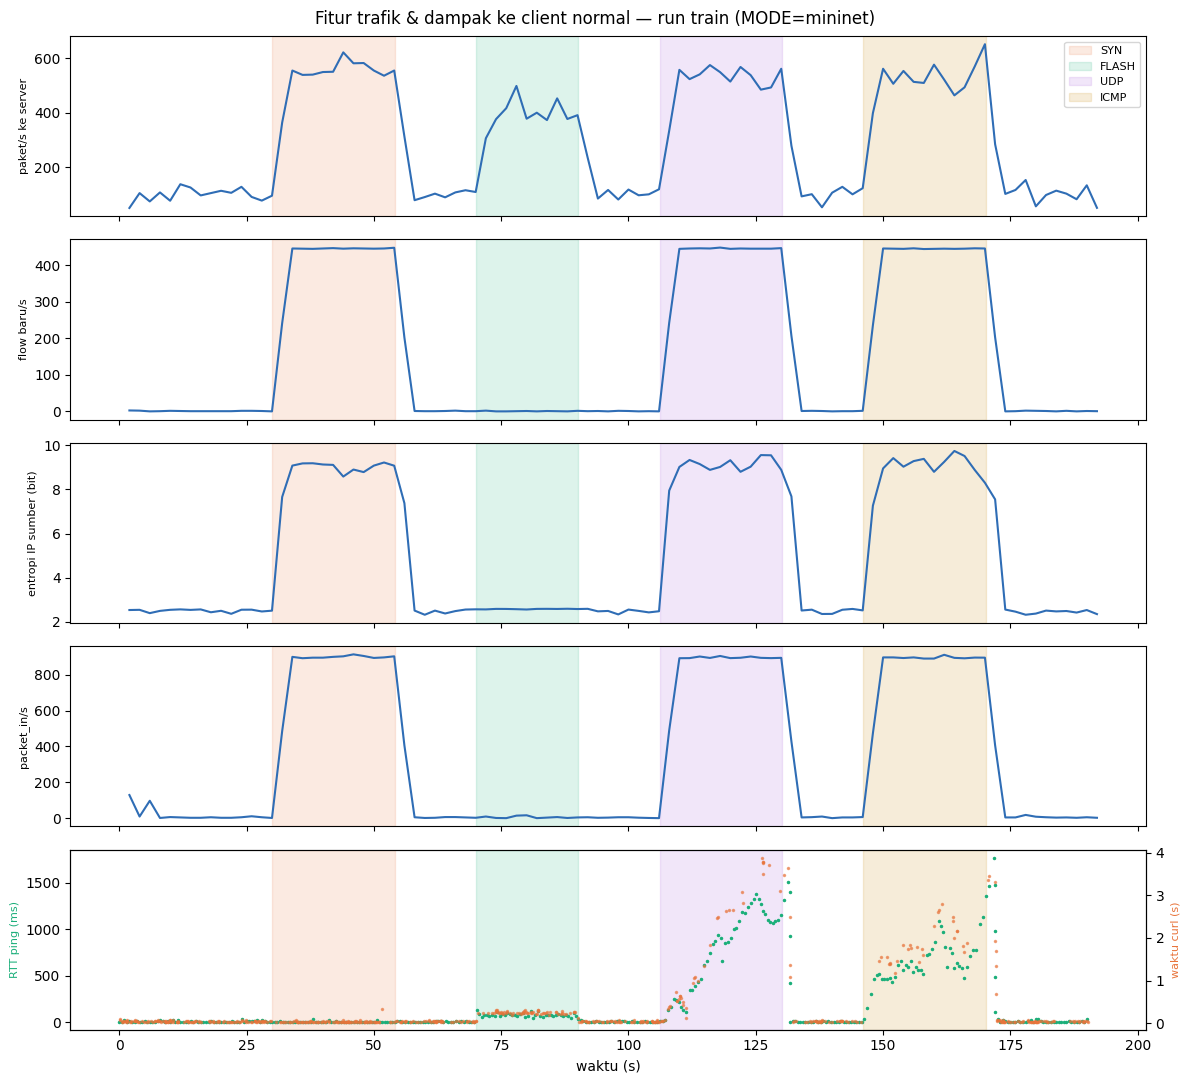

In [8]:
def shade_phases(ax, run, t0):
    colors = {"syn": "#e8743b", "udp": "#a259d9", "icmp": "#c98500", "flash": "#1baf7a"}
    for _, p in run["phases"].iterrows():
        if p.phase != "normal":
            ax.axvspan(p.start - t0, p.end - t0, color=colors.get(p.phase, "red"), alpha=0.15, label=p.phase.upper())

run, t0 = runs["train"], runs["train"]["t0"]
tt = nf_train.index * STATS_INTERVAL
fig, axes = plt.subplots(5, 1, figsize=(12, 11), sharex=True)
for ax, (col, lbl) in zip(axes, [("pkt_rate", "paket/s ke server"), ("new_flow_rate", "flow baru/s"),
                                 ("src_entropy", "entropi IP sumber (bit)"), ("pktin_rate", "packet_in/s")]):
    ax.plot(tt, nf_train[col], color="#2f6db5"); ax.set_ylabel(lbl, fontsize=8); shade_phases(ax, run, t0)
imp = run["impact"]
x = imp[imp.metric == "ping_ms"]
axes[4].plot(x.ts - t0, x.value, ".", ms=3, color="#1baf7a")
x = imp[imp.metric == "curl_s"]
axc = axes[4].twinx(); axc.plot(x.ts - t0, x.value, ".", ms=3, color="#e8743b", alpha=0.6); axc.set_ylabel("waktu curl (s)", fontsize=8, color="#e8743b")
axes[4].set_ylabel("RTT ping (ms)", fontsize=8, color="#1baf7a"); shade_phases(axes[4], run, t0)
h, l = axes[0].get_legend_handles_labels(); axes[0].legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), loc="upper right", fontsize=8)
axes[-1].set_xlabel("waktu (s)")
fig.suptitle(f"Fitur trafik & dampak ke client normal — run train (MODE={MODE})")
plt.tight_layout(); plt.savefig(RES / "timeline_fitur.png", dpi=150); plt.show()

## 5. Deteksi
### 5a. Baseline statistik: z-score / entropi
Profil normal (rata-rata & simpangan baku) dari jendela normal data latih; alarm bila |z| salah satu fitur kunci > `ZSCORE_THRESHOLD`. Spoofing membuat entropi IP sumber melonjak, flood tanpa spoofing membuatnya turun — keduanya menyimpang dari profil normal. Kelemahannya: **flash crowd** (lonjakan trafik sah) juga menyimpang dari profil normal sehingga memicu false alarm.

In [9]:
if TEST_ON_SECOND_RUN:
    nf_tr, nf_te = nf_train, datasets["test"][0]
    sf_tr, sf_te = sf_train, datasets["test"][1]
    split_note = "latih = run 1, uji = run 2 (skenario terpisah)"
else:
    nf_tr, nf_te = train_test_split(nf_train, test_size=0.3, stratify=nf_train.label, random_state=SEED)
    sf_tr, sf_te = train_test_split(sf_train, test_size=0.3, stratify=sf_train.label, random_state=SEED)
    split_note = "split acak terstratifikasi 70/30 dari satu run"
print("Skema evaluasi:", split_note)

def scores(y, p):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p, zero_division=0),
                recall=recall_score(y, p, zero_division=0), f1=f1_score(y, p, zero_division=0),
                false_alarm_rate=fp / max(fp + tn, 1))

Z_FEATURES = ["pkt_rate", "new_flow_rate", "src_entropy", "kbps", "pktin_rate"]
normal = nf_tr[nf_tr.phase == "normal"][Z_FEATURES]
mu, sd = normal.mean(), np.maximum(normal.std(), np.maximum(0.1 * normal.mean().abs(), 1e-3))
def zscore_detect(df):
    return (((df[Z_FEATURES] - mu) / sd).abs() > ZSCORE_THRESHOLD).any(axis=1).astype(int)

results = {"Z-score/Entropi": scores(nf_te.label, zscore_detect(nf_te))}
print(pd.DataFrame(results).T.round(3))
fl = nf_te[nf_te.phase == "flash"]
if len(fl):
    print(f"Jendela flash crowd yang dianggap serangan oleh z-score: {zscore_detect(fl).sum()}/{len(fl)}")

Skema evaluasi: split acak terstratifikasi 70/30 dari satu run
                 accuracy  precision  recall     f1  false_alarm_rate
Z-score/Entropi     0.828      0.688     1.0  0.815             0.278
Jendela flash crowd yang dianggap serangan oleh z-score: 4/4


### 5b. Machine learning (level jaringan)

,accuracy,precision,recall,f1,false_alarm_rate,train_ms,false_alarm_flash
Z-score/Entropi,0.828,0.688,1.0,0.815,0.278,NaN,4/4
Decision Tree,1.000,1.000,1.0,1.000,0.000,13.697,0/4
Random Forest,1.000,1.000,1.0,1.000,0.000,261.418,0/4
KNN,1.000,1.000,1.0,1.000,0.000,17.732,0/4
SVM (RBF),1.000,1.000,1.0,1.000,0.000,9.926,0/4


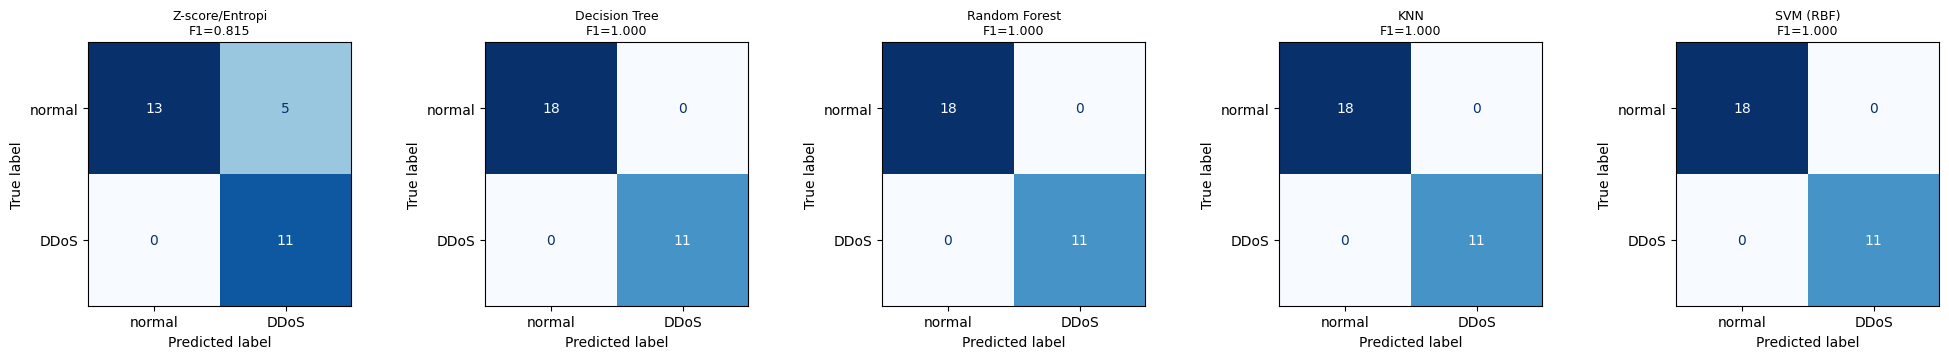

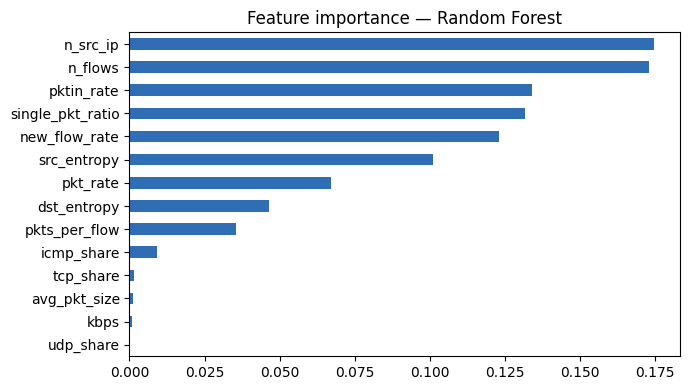

In [10]:
MODELS = {
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=3, gamma="scale")),
}
preds = {}
flash_fa = {"Z-score/Entropi": int(zscore_detect(fl).sum()) if len(fl) else 0}
for name, model in MODELS.items():
    t = time.perf_counter()
    model.fit(nf_tr[NET_FEATURES], nf_tr.label)
    preds[name] = model.predict(nf_te[NET_FEATURES])
    results[name] = scores(nf_te.label, preds[name]) | {"train_ms": (time.perf_counter() - t) * 1000}
    flash_fa[name] = int(preds[name][(nf_te.phase == "flash").values].sum())
res_df = pd.DataFrame(results).T
res_df["false_alarm_flash"] = pd.Series(flash_fa).astype(str) + f"/{len(fl)}"
res_df.to_csv(RES / "hasil_deteksi_level_jaringan.csv")
display(res_df.round(3))

fig, axes = plt.subplots(1, len(MODELS) + 1, figsize=(4 * (len(MODELS) + 1), 3.6))
for ax, (name, p) in zip(axes, [("Z-score/Entropi", zscore_detect(nf_te))] + list(preds.items())):
    ConfusionMatrixDisplay(confusion_matrix(nf_te.label, p, labels=[0, 1]), display_labels=["normal", "DDoS"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nF1={results[name]['f1']:.3f}", fontsize=9)
plt.tight_layout(); plt.savefig(RES / "confusion_matrix.png", dpi=150); plt.show()

rf = MODELS["Random Forest"]
imp_s = pd.Series(rf.feature_importances_, index=NET_FEATURES).sort_values()
ax = imp_s.plot.barh(figsize=(7, 4), color="#2f6db5"); ax.set_title("Feature importance — Random Forest")
plt.tight_layout(); plt.savefig(RES / "feature_importance.png", dpi=150); plt.show()

### 5c. Klasifikasi jenis serangan & identifikasi port sumber

Akurasi klasifikasi jenis trafik (normal/flash/syn/udp/icmp): 0.966
Klasifikasi port sumber serangan: {'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'false_alarm_rate': np.float64(0.0)}


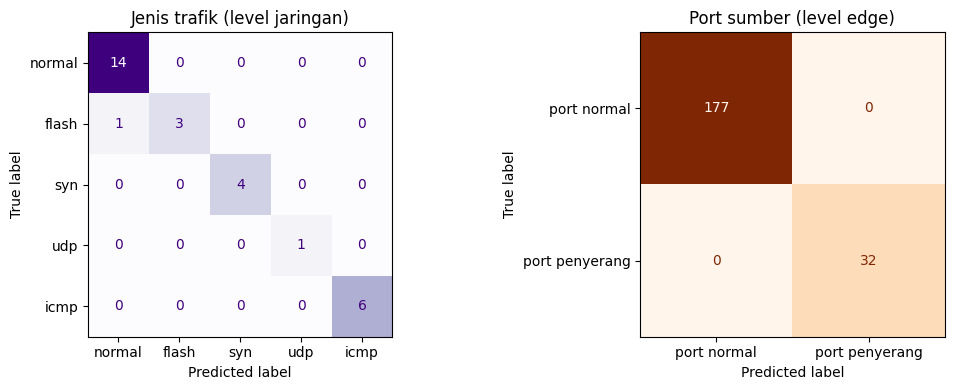

In [11]:
rf_type = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(nf_tr[NET_FEATURES], nf_tr.phase)
p_type = rf_type.predict(nf_te[NET_FEATURES])
labels = [p for p in ["normal", "flash"] + ATTACK_TYPES if p in set(nf_tr.phase)]
print(f"Akurasi klasifikasi jenis trafik ({'/'.join(labels)}): {accuracy_score(nf_te.phase, p_type):.3f}")

src_model = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1, class_weight="balanced")
src_model.fit(sf_tr[SRC_FEATURES], sf_tr.label)
p_src = src_model.predict(sf_te[SRC_FEATURES])
src_scores = scores(sf_te.label, p_src)
print("Klasifikasi port sumber serangan:", {k: round(v, 3) for k, v in src_scores.items()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(nf_te.phase, p_type, labels=labels), display_labels=labels).plot(ax=axes[0], colorbar=False, cmap="Purples")
axes[0].set_title("Jenis trafik (level jaringan)")
ConfusionMatrixDisplay(confusion_matrix(sf_te.label, p_src, labels=[0, 1]), display_labels=["port normal", "port penyerang"]).plot(ax=axes[1], colorbar=False, cmap="Oranges")
axes[1].set_title("Port sumber (level edge)")
plt.tight_layout(); plt.savefig(RES / "jenis_dan_sumber.png", dpi=150); plt.show()

## 6. Demo online: deteksi + mitigasi otomatis
Serangan baru (`ONLINE_DEMO['attack']`) dijalankan setelah `pre` detik. Tiap interval:
1. flow stats terbaru → fitur jendela → **Random Forest level jaringan** memutuskan ada serangan atau tidak;
2. bila ada, **model port sumber** menandai port edge yang mencurigakan; port yang ditandai `consecutive` jendela berturut-turut dimasukkan ke `blocklist.json`;
3. Ryu memasang drop rule pada `(dpid, in_port)` tersebut → trafik penyerang berhenti di edge.

In [12]:
class OnlineDetector:
    def __init__(self, net_model, src_model, consecutive):
        self.net_model, self.src_model, self.consecutive = net_model, src_model, consecutive
        self.flag_count = defaultdict(int)
        self.blocked = {}
        self.timeline = []

    def process(self, w, fd, pk, t0, ts):
        nf = network_features(fd[fd.win == w], pk, t0, windows=[w])
        attack = int(self.net_model.predict(nf[NET_FEATURES])[0])
        new_blocks = []
        flagged = set()
        if attack:
            sf = source_features(fd[fd.win == w])
            if len(sf):
                sf = sf[[(d, p) not in self.blocked for d, p in zip(sf.dpid, sf.in_port)]]
                if len(sf):
                    flagged = {(d, p) for d, p, y in zip(sf.dpid, sf.in_port, self.src_model.predict(sf[SRC_FEATURES])) if y}
        for port in list(self.flag_count):
            if port not in flagged:
                self.flag_count[port] = 0
        for port in flagged:
            self.flag_count[port] += 1
            if self.flag_count[port] >= self.consecutive and port not in self.blocked:
                self.blocked[port] = ts
                new_blocks.append(port)
        self.timeline.append(dict(win=w, ts=ts, attack_pred=attack, flagged=len(flagged),
                                  blocked=len(self.blocked), **nf.iloc[0][["pkt_rate", "new_flow_rate", "src_entropy"]].to_dict()))
        return new_blocks

class CsvTail:
    """Membaca baris baru dari CSV yang terus ditambah oleh Ryu."""
    def __init__(self, path, cols):
        self.path, self.cols = Path(path), cols
        self.offset = self.path.stat().st_size if self.path.exists() else 0
    def read(self):
        if not self.path.exists():
            return pd.DataFrame(columns=self.cols)
        with open(self.path, "rb") as f:
            f.seek(self.offset)
            chunk = f.read()
        end = chunk.rfind(b"\n") + 1
        self.offset += end
        lines = [l.split(",") for l in chunk[:end].decode(errors="ignore").splitlines() if l and not l.startswith("ts,")]
        return to_numeric_cols(pd.DataFrame(lines, columns=self.cols))

def online_demo(cfg):
    det = OnlineDetector(MODELS["Random Forest"], src_model, cfg["consecutive"])
    total = cfg["pre"] + cfg["duration"] + cfg["post"]
    events, version = [], 0
    if MODE == "mininet":
        logdir = RUNTIME / "online"; logdir.mkdir(exist_ok=True)
        for f in logdir.glob("*.log"):
            f.unlink()
        write_blocklist([], 0)
        tail_f, tail_p = CsvTail(FLOW_CSV, FLOW_COLS), CsvTail(PKTIN_CSV, PKTIN_COLS)
        t0 = time.time()
        start_background(logdir, t0 + total + 2)
        for a in ATTACKERS:
            net.get(a).cmd(f"(sleep {cfg['pre']}; timeout {cfg['duration']} hping3 {hping_args(cfg['attack'])} {SERVER_IP}) > /dev/null 2>&1 &")
        raw, pkd, done = pd.DataFrame(columns=FLOW_COLS + ["win"]), pd.DataFrame(columns=PKTIN_COLS), set()
        while time.time() < t0 + total:
            time.sleep(STATS_INTERVAL / 2)
            new_f, new_p = tail_f.read(), tail_p.read()
            if len(new_f):
                raw = pd.concat([raw, add_win(new_f, t0)], ignore_index=True)
            if len(new_p):
                pkd = pd.concat([pkd, new_p], ignore_index=True)
            if raw.empty:
                continue
            for w in sorted(set(raw.win.unique()) - done):
                if w >= raw.win.max():                    # jendela terakhir mungkin belum lengkap
                    continue
                done.add(w)
                if w < 2:                                 # jendela pemanasan
                    continue
                fd = flow_deltas(raw[raw.win.isin([w - 1, w])].drop(columns="win"), t0)
                for port in det.process(w, fd, pkd, t0, time.time()):
                    version += 1
                    write_blocklist([{"dpid": d, "in_port": p, "timeout": cfg["block_timeout"]} for d, p in det.blocked], version)
                    events.append(dict(ts=time.time(), port=port, host=PORT2HOST.get(port, "?")))
                    print(f"  ⛔ t={time.time() - t0:5.1f}s blokir dpid={port[0]} port={port[1]} ({PORT2HOST.get(port, '?')})")
        stop_background()
        impact = parse_impact(logdir)
        write_blocklist([], version + 1)                  # buka blokir setelah demo
    else:
        sim = SimDDoSNet(SEED + 99)
        for _ in range(3):
            sim.step("normal")
        t0, prev, pk, imp = sim.t, [], [], []
        for k in range(int(total / STATS_INTERVAL)):
            el = (k + 0.5) * STATS_INTERVAL
            phase = cfg["attack"] if cfg["pre"] <= el < cfg["pre"] + cfg["duration"] else "normal"
            f, p, i = sim.step(phase)
            pk += p; imp += i
            fd = flow_deltas(pd.DataFrame(prev + f, columns=FLOW_COLS), t0)
            prev = f
            w = int(fd.win.max())
            if w < 2:
                continue
            for port in det.process(w, fd, pd.DataFrame(pk, columns=PKTIN_COLS), t0, sim.t):
                sim.blocked.add(port)
                events.append(dict(ts=sim.t, port=port, host=PORT2HOST.get(port, "?")))
                print(f"  ⛔ t={sim.t - t0:5.1f}s blokir dpid={port[0]} port={port[1]} ({PORT2HOST.get(port, '?')})")
        impact = pd.DataFrame(imp, columns=["ts", "metric", "value"])
    return dict(t0=t0, timeline=pd.DataFrame(det.timeline), events=pd.DataFrame(events, columns=["ts", "port", "host"]),
                impact=impact, attack_start=t0 + cfg["pre"], attack_end=t0 + cfg["pre"] + cfg["duration"])

print(f"▶ Demo online: serangan {ONLINE_DEMO['attack'].upper()} mulai t={ONLINE_DEMO['pre']} s selama {ONLINE_DEMO['duration']} s")
demo = online_demo(ONLINE_DEMO)

▶ Demo online: serangan UDP mulai t=12 s selama 50 s


/tmp/ipykernel_2869/3756597939.py:66: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  raw = pd.concat([raw, add_win(new_f, t0)], ignore_index=True)
/tmp/ipykernel_2869/3756597939.py:68: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pkd = pd.concat([pkd, new_p], ignore_index=True)
/tmp/ipykernel_2869/673155340.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to

  ⛔ t= 17.8s blokir dpid=2 port=3 (h3)
  ⛔ t= 17.8s blokir dpid=3 port=3 (h6)
  ⛔ t= 17.8s blokir dpid=4 port=3 (h9)


/tmp/ipykernel_2869/673155340.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["pktin_rate"] = pkw.reindex(out.index).fillna(0).values / STATS_INTERVAL
/tmp/ipykernel_2869/673155340.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["pktin_rate"] = pkw.reindex(out.index).fillna(0).values / STATS_INTERVAL
/tmp/ipykernel_2869/673155340.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavio

jeda deteksi (s)              : 3.5
jeda mitigasi penuh (s)       : 5.8
port diblokir                 : ['h3', 'h6', 'h9']
penyerang terblokir           : 3/3
client normal ikut terblokir  : []
jendela false alarm           : 0


,RTT ping (ms),waktu curl (s)
sebelum serangan,7.667,0.041
"serangan, sebelum mitigasi",321.714,0.579
setelah mitigasi,8.488,0.041


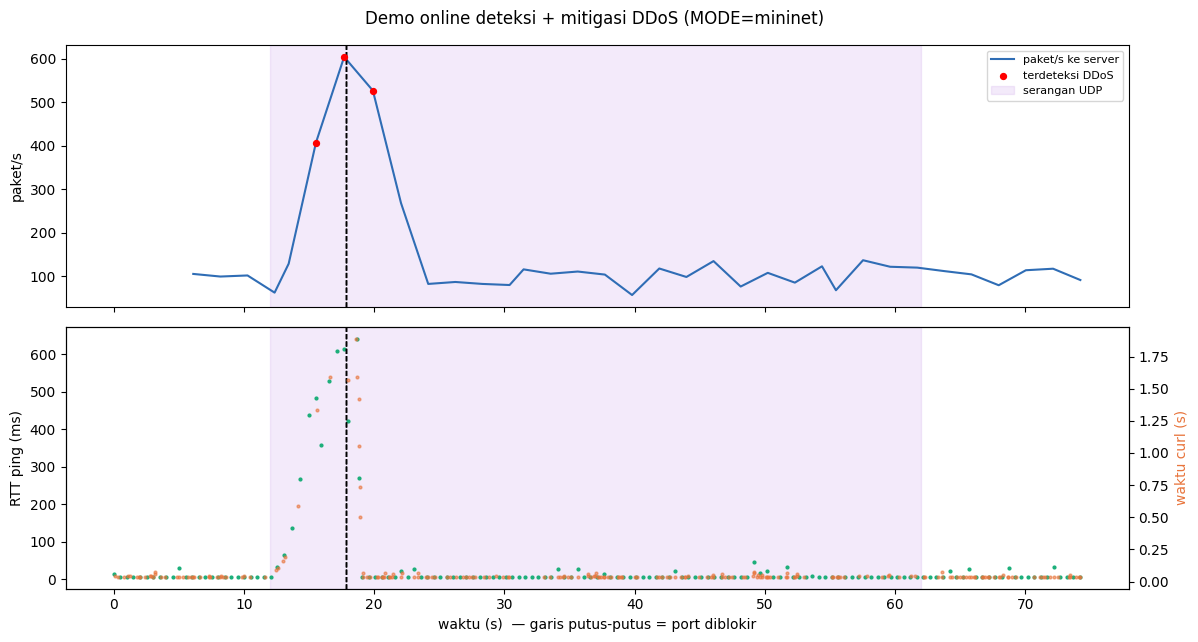

In [13]:
t0, tl, ev, imp = demo["t0"], demo["timeline"], demo["events"], demo["impact"]
a0, a1 = demo["attack_start"] - t0, demo["attack_end"] - t0
first_det = tl[(tl.attack_pred == 1) & (tl.ts - t0 >= a0)]
det_delay = (first_det.ts.iloc[0] - t0 - a0) if len(first_det) else np.nan
false_alarm = int(((tl.attack_pred == 1) & ((tl.ts - t0 < a0) | (tl.ts - t0 > a1 + 2 * STATS_INTERVAL))).sum())
blocked_hosts = list(ev.host)
mitig_delay = (ev.ts.max() - t0 - a0) if len(ev) else np.nan

def window_stats(df, lo, hi, metric):
    x = df[(df.metric == metric) & (df.ts - t0 >= lo) & (df.ts - t0 < hi)].value
    return x.mean() if len(x) else np.nan
t_mit = (ev.ts.max() - t0) if len(ev) else a1
periods = {"sebelum serangan": (0, a0), "serangan, sebelum mitigasi": (a0, t_mit),
           "setelah mitigasi": (t_mit + STATS_INTERVAL, a1)}
impact_tbl = pd.DataFrame({k: {"RTT ping (ms)": window_stats(imp, *v, "ping_ms"),
                               "waktu curl (s)": window_stats(imp, *v, "curl_s")} for k, v in periods.items()}).T
summary = {"jeda deteksi (s)": det_delay, "jeda mitigasi penuh (s)": mitig_delay,
           "port diblokir": blocked_hosts,
           "penyerang terblokir": f"{len(set(blocked_hosts) & set(ATTACKERS))}/{len(ATTACKERS)}",
           "client normal ikut terblokir": sorted(set(blocked_hosts) - set(ATTACKERS)),
           "jendela false alarm": false_alarm}
for k, v in summary.items():
    print(f"{k:<30}: {round(v, 1) if isinstance(v, float) else v}")
display(impact_tbl.round(3))
impact_tbl.to_csv(RES / "demo_online_dampak.csv")
tl.to_csv(RES / "demo_online_timeline.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax = axes[0]
ax.plot(tl.ts - t0, tl.pkt_rate, color="#2f6db5", label="paket/s ke server")
ax.scatter(tl.ts[tl.attack_pred == 1] - t0, tl.pkt_rate[tl.attack_pred == 1], color="red", s=18, zorder=3, label="terdeteksi DDoS")
ax.set_ylabel("paket/s")
axes[1].plot(imp[imp.metric == "ping_ms"].ts - t0, imp[imp.metric == "ping_ms"].value, ".", ms=4, color="#1baf7a", label="RTT ping (ms)")
axes[1].set_ylabel("RTT ping (ms)")
axc = axes[1].twinx()
x = imp[imp.metric == "curl_s"]
axc.plot(x.ts - t0, x.value, ".", ms=4, color="#e8743b", alpha=0.6); axc.set_ylabel("waktu curl (s)", color="#e8743b")
for a in axes:
    a.axvspan(a0, a1, color="#a259d9", alpha=0.12, label=f"serangan {ONLINE_DEMO['attack'].upper()}")
    for t in ev.ts:
        a.axvline(t - t0, color="black", ls="--", lw=1)
axes[0].legend(fontsize=8, loc="upper right"); axes[-1].set_xlabel("waktu (s)  — garis putus-putus = port diblokir")
fig.suptitle(f"Demo online deteksi + mitigasi DDoS (MODE={MODE})")
plt.tight_layout(); plt.savefig(RES / "demo_online.png", dpi=150); plt.show()

## 7. Penutup

In [14]:
shutdown()
print("Emulasi dihentikan." if MODE == "mininet" else "Mode simulasi selesai.")
for f in sorted(RES.iterdir()):
    print(f"  {f.relative_to(BASE)}  ({f.stat().st_size / 1024:.1f} KB)")

Emulasi dihentikan.
  results/02_ddos/confusion_matrix.png  (37.7 KB)
  results/02_ddos/demo_online.png  (118.3 KB)
  results/02_ddos/demo_online_dampak.csv  (0.2 KB)
  results/02_ddos/demo_online_timeline.csv  (2.0 KB)
  results/02_ddos/feature_importance.png  (46.3 KB)
  results/02_ddos/flow_stats_train.csv  (15015.7 KB)
  results/02_ddos/hasil_deteksi_level_jaringan.csv  (0.4 KB)
  results/02_ddos/jenis_dan_sumber.png  (47.7 KB)
  results/02_ddos/timeline_fitur.png  (222.5 KB)


### Ide eksperimen lanjutan
1. `ATTACK_SPOOF = False`: flood dari IP asli — fitur entropi berubah arah, flow baru jauh lebih sedikit; bandingkan feature importance.
2. Turunkan `ATTACK_RATE_PPS` (serangan *low-rate*) dan amati recall tiap model.
3. Tambah serangan baru di `hping_args` (mis. ACK flood `-A`, atau *slow* SYN `-i u100000`) tanpa melatih ulang → uji generalisasi.
4. Ubah granularitas flow di `ddos_monitor.py` (mis. tambah `tcp_dst`/`udp_dst`) dan lihat dampaknya ke beban controller (`pktin_rate`).
5. Ganti mitigasi berbasis port dengan *rate limiting* memakai OpenFlow meter (`OFPMeterMod`) agar host yang tertandai tidak diputus total.